# Importações

In [1]:
import pandas as pd 
import os 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# filtro de warnings
import warnings
warnings.filterwarnings('ignore')


In [2]:
# funçoes e classes auxiliares 
# Classe para carregamento das bases 
class tables_load():
    def table_base_cadastral(self, verbose=True):
        if verbose == True: 
            data_path = os.path.join('..', 'data', 'raw', 'base_cadastral.parquet')
            if os.path.exists(data_path) != True:
                raise AttributeError('Arquivo nao encontrado')
            df = pd.read_parquet(data_path)
            print('==='*50)
            print(f'Dimensoes da tabela de cadastro:')
            print('==='*50)
            print(f'linhas: {df.shape[0]}')
            print(f'colunas: {df.shape[1]}')
            return df.set_index('id_cliente')
        
    def table_base_emprestimos(self, verbose=True):
        if verbose == True:
            data_path = os.path.join('..', 'data', 'raw', 'historico_emprestimos.parquet')
            if os.path.exists(data_path) != True:
                    raise AttributeError('Arquivo nao encontrado')
            df = pd.read_parquet(data_path)
            print('==='*50)
            print(f'Dimensoes da tabela de emprestimos:')
            print('==='*50)
            print(f'linhas: {df.shape[0]}')
            print(f'colunas: {df.shape[1]}')
            return df.set_index(['id_cliente', 'id_contrato'])
        
    def table_base_parcelas(self, verbose=True):
        if verbose == True:
            data_path = os.path.join('..', 'data', 'raw', 'historico_parcelas.parquet')
            if os.path.exists(data_path) != True:
                raise AttributeError('Arquivo nao encontrado')
            df = pd.read_parquet(data_path)
            print('==='*50)
            print(f'Dimensoes da tabela de parcelas:')
            print('==='*50)
            print(f'linhas: {df.shape[0]}')
            print(f'colunas: {df.shape[1]}')
            return df.set_index(['id_cliente', 'id_contrato'])

# funçao para filtro de nulos
def is_null(data:pd.DataFrame, limiar:float):
    df_null = data.isnull().mean().sort_values(ascending=False)
    print('======'*40)
    print(f'COLUNAS COM % DE NAN MAIOR QUE {limiar}')
    print('======'*40)
    print
    col_return = []
    k =0 
    for name, num in df_null.items() :
        if num >=limiar:
            print(f'{name}: {num}')
            k+=1
            col_return.append(name)
    print(f'quantidade de colunas nulas em funçao do limiar: {k}')

# classe para plot de distribuiçoes
class PlotDistribution():
    def cat_plot(self, data:pd.DataFrame, cat_data):
        if isinstance(data[cat_data], pd.Series):
            print(f'plotando Coluna: {cat_data}')
            plt.figure(figsize=(12,8))
            plt.title(f'{cat_data}')
            ax1 = sns.countplot(data[cat_data], palette='viridis')
            for container in ax1.containers:
                ax1.bar_label(container, fontsize=10)
            plt.xlabel('Contagem')
            plt.tight_layout()
            plt.show()
            
        if isinstance(cat_data, list):
            fig, axes = plt.subplots(figsize=(16, 7 * len(cat_data)), ncols=1, nrows=len(cat_data))
            for cat, ax in zip(cat_data, axes):
                ax1 = sns.countplot(x=data[cat], ax=ax, palette='viridis')
                ax.set_ylabel('Contagem')
                ax.set_title(f'{cat}')
                ax.tick_params(axis='x', rotation=90)
                for container in ax1.containers:
                    ax1.bar_label(container, fontsize=10)
            plt.tight_layout()
            plt.show()
        else:
            print(f'Inpute uma tabela ou uma Serie válida')
            
    def num_plot(self, data: pd.DataFrame, num_data):
        if isinstance(data[num_data], pd.Series):
            fig, axes = plt.subplots(figsize=(12,8), ncols=2, nrows=1)
            sns.boxplot(data[num_data], ax=axes[0], fill=False, color='black')
            sns.histplot(data[num_data], kde=True, ax=axes[1], color='blue')
            axes[0].set_title(f'Boxplot - {num_data}')
            axes[1].set_title(f'Histograma - {num_data}')
            fig.tight_layout()
            fig.show()
        if isinstance(num_data, list):
            fig, axes = plt.subplots(figsize=(24,30), ncols=2, nrows=len(num_data))
            for i, num in enumerate(num_data):
                sns.boxplot(data[num], ax=axes[i,0], fill=False, color='black')
                sns.histplot(data[num], ax=axes[i,1], kde=True,color='blue')
                axes[i,0].set_title(f'BoxPlot - {num}')
                axes[i,1].set_title(f'Histograma - {num}')
            fig.tight_layout()
            fig.show()
        else:
            print(f'Inpute uma tabela ou uma Serie válida')

# funçao para contagem de id's duplicados
def duplicated_id(col:pd.DataFrame, id:str):
    data = col.reset_index()
    if not isinstance(col, pd.Series):
        ValueError('Use uma Série válida')
    if isinstance(id, str):
        count = data.duplicated(subset=f'{id}').sum()
        if count >1:
            id_unique = data[id].nunique()
            print('==='*50)
            print(f'Frequencia - Contagem de Id duplicado')
            print('==='*50)
            print()
            print(f"total id's unicos: {id_unique}")
            print(f"contagem id's duplicados: {count}")
        else:
            print('Nenhum id duplicado encontrado')

# teste de criaçao do target 
def target_create(DPD:int):
    df_parcelas['dias_atraso'] = (df_parcelas['data_real_pagamento']- df_parcelas['data_prevista_pagamento']).dt.days
    df_parcelas['TARGET'] = np.where(df_parcelas['dias_atraso']>DPD,1,0)
    return df_parcelas
    

# Tratamento de Dados

Nessa etapa, tratarei os dados de todas as tabelas antes da exploração e analises

In [3]:
# carregando tabelas
df_cadastro = tables_load().table_base_cadastral()
df_emprestimos = tables_load().table_base_emprestimos()
df_parcelas = tables_load().table_base_parcelas()

Dimensoes da tabela de cadastro:
linhas: 50600
colunas: 16
Dimensoes da tabela de emprestimos:
linhas: 211944
colunas: 37
Dimensoes da tabela de parcelas:
linhas: 1664384
colunas: 8


In [4]:
df_emprestimos['indicador_ultima_solicitacao_contrato'].value_counts()

indicador_ultima_solicitacao_contrato
Sim    210894
Não      1050
Name: count, dtype: int64

# Trabalhando com a tabela cadastro

In [5]:
df_cadastro.head()

,sexo,data_nascimento,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade
id_cliente,,,,,,,,,,,,,,,
100023,Feminino,1994-01-30,1,2.0,"90.000,00",Servidor público,Equipe administrativa,Educação infantil,Ensino superior,Solteiro,Casa ou apartamento,Não,Sim,2,2
100031,Feminino,1973-11-13,0,1.0,"112.500,00",Assalariado,Cozinheiros,Entidade empresarial tipo 3,Ensino médio,Viúvo,Casa ou apartamento,Não,Sim,3,2
100056,Masculino,1975-02-19,0,2.0,"360.000,00",Assalariado,Operários,Transporte tipo 2,Ensino médio,Casado,Casa ou apartamento,Sim,Sim,2,2
100069,Masculino,1986-04-10,1,2.0,"360.000,00",Assalariado,Operários,Transporte tipo 4,Ensino médio,Separado,Casa ou apartamento,Sim,Sim,2,2
100085,Masculino,1994-07-05,1,3.0,"-17.673,00",Assalariado,Motoristas,Entidade empresarial tipo 1,Ensino médio,Casado,Casa ou apartamento,Não,Sim,2,2


In [6]:
df_cadastro.info()

<class 'pandas.DataFrame'>
Index: 50600 entries, 100023 to 317001
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   sexo                        50600 non-null  object 
 1   data_nascimento             50600 non-null  object 
 2   qtd_filhos                  50600 non-null  int64  
 3   qtd_membros_familia         50600 non-null  float64
 4   renda_anual                 50600 non-null  object 
 5   tipo_renda                  50600 non-null  object 
 6   ocupacao                    34894 non-null  object 
 7   tipo_organizacao            50600 non-null  object 
 8   nivel_educacao              50600 non-null  object 
 9   estado_civil                50600 non-null  object 
 10  tipo_moradia                50600 non-null  object 
 11  possui_carro                50600 non-null  object 
 12  possui_imovel               50600 non-null  object 
 13  nota_regiao_cliente         50600 non-nul

In [7]:
# verificando nulos tabela cadastro - limiar de 30%
is_null(df_cadastro, 0.3)

COLUNAS COM % DE NAN MAIOR QUE 0.3
ocupacao: 0.31039525691699604
quantidade de colunas nulas em funçao do limiar: 1


In [8]:
# verificando percentuais de ocupaçao
df_cadastro['ocupacao'].value_counts(normalize=True)

ocupacao
Operários                          0.258669
Equipe de vendas                   0.159626
Equipe administrativa              0.132860
Gerentes                           0.105577
Motoristas                         0.092308
Técnicos especializados            0.058033
Contadores                         0.048576
Profissionais de saúde             0.042643
Equipe de segurança                0.026337
Cozinheiros                        0.022010
Equipe de limpeza                  0.016908
Serviços particulares              0.010403
Operários de baixa qualificação    0.007365
Garçons e atendentes de bar        0.005789
Secretárias                        0.005273
Corretores imobiliários            0.003009
Equipe de tecnologia               0.002436
Equipe de recursos humanos         0.002178
Name: proportion, dtype: float64

In [9]:
# pegando 10 amostras aleatorias onde a ocupaçao é nula
df_cadastro[df_cadastro['ocupacao'].isna()].sample(10)

,sexo,data_nascimento,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade
id_cliente,,,,,,,,,,,,,,,
271848,Feminino,1967-02-07,0,2.0,"144.000,00",Assalariado,None,Autônomo,Ensino médio,Casado,Casa ou apartamento,Sim,Sim,2,2
151503,Masculino,1962-04-05,0,2.0,"112.500,00",Aposentado,None,Não informado,Ensino superior,Casado,Casa ou apartamento,Sim,Sim,2,2
210432,Feminino,1974-02-20,0,2.0,"193.500,00",Associado comercial,None,Escola,Ensino superior,Casado,Casa ou apartamento,Não,Sim,2,2
105358,Feminino,1970-10-12,0,2.0,"112.500,00",Associado comercial,None,Governo,Ensino médio,Casado,Casa ou apartamento,Não,Sim,2,2
278295,Feminino,2003-01-17,1,3.0,"135.000,00",Associado comercial,None,Entidade empresarial tipo 3,Ensino superior,Casado,Casa ou apartamento,SIM,Sim,2,2
100512,Feminino,1960-04-13,0,1.0,"92.250,00",Aposentado,None,Não informado,Ensino médio,Solteiro,Casa ou apartamento,Não,Sim,2,2
378157,Feminino,1971-11-04,0,1.0,"135.000,00",Assalariado,None,Indústria tipo 11,Ensino superior,Separado,Casa ou apartamento,Não,Sim,2,2
461779,Feminino,1987-11-21,0,2.0,"301.500,00",Aposentado,None,Autônomo,Ensino superior,Casado,Casa ou apartamento,Sim,Não,3,3
462331,Masculino,1988-02-10,0,2.0,"106.000,00",Assalariado,None,Autônomo,Ensino superior,Casado,Casa ou apartamento,Não,Não,3,3


In [10]:
# para a coluna ocupaçao, preencherei os dados faltantes como "nao informado", aplicando granularidade a variavel, sem precisar excluir as linhas nulas ou até  a coluna inteira 
df_cadastro['ocupacao'] = df_cadastro['ocupacao'].fillna('Não informado')

In [11]:
df_cadastro['ocupacao'].value_counts(normalize=True)

ocupacao
Não informado                      0.310395
Operários                          0.178379
Equipe de vendas                   0.110079
Equipe administrativa              0.091621
Gerentes                           0.072806
Motoristas                         0.063656
Técnicos especializados            0.040020
Contadores                         0.033498
Profissionais de saúde             0.029407
Equipe de segurança                0.018162
Cozinheiros                        0.015178
Equipe de limpeza                  0.011660
Serviços particulares              0.007174
Operários de baixa qualificação    0.005079
Garçons e atendentes de bar        0.003992
Secretárias                        0.003636
Corretores imobiliários            0.002075
Equipe de tecnologia               0.001680
Equipe de recursos humanos         0.001502
Name: proportion, dtype: float64

In [12]:
# transformando a coluna data de nascimento em idade
df_cadastro['data_nascimento'] = pd.to_datetime(df_cadastro['data_nascimento'], format='%Y-%m-%d', errors='coerce')
data_hoje = pd.Timestamp.today().normalize()
df_cadastro['idade'] = (data_hoje.year - df_cadastro['data_nascimento'].dt.year-((df_cadastro['data_nascimento'].dt.month > data_hoje.month) | ((df_cadastro['data_nascimento'].dt.month == data_hoje.month) & (df_cadastro['data_nascimento'].dt.day > data_hoje.day))).astype('Int64'))
df_cadastro.drop('data_nascimento', axis=1, inplace=True)

In [13]:
# verificando labels das colunas possui_carro e possui_imovel
labels_count = ['possui_imovel', 'possui_carro']
for label in labels_count:
    print(f'COLUNA: {label}')
    print(df_cadastro[label].value_counts(normalize=True))
    print('-----'*50)

COLUNA: possui_imovel
possui_imovel
Sim              0.690217
Não              0.304783
Não              0.001146
não informado    0.001067
SIM              0.000988
nao              0.000929
sim              0.000870
Name: proportion, dtype: float64
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
COLUNA: possui_carro
possui_carro
Não              0.652727
Sim              0.342273
Não              0.001107
nao              0.001047
sim              0.000968
não informado    0.000968
SIM              0.000909
Name: proportion, dtype: float64
---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

As Colunas em questão possuem espaços e caracteres diferentes uma das outras, com isso, unificarei a formatação

In [14]:
# unificando a formataçao das colunas 
for labels_lower in labels_count:
    print(f'modificando coluna: {labels_lower}')
    df_cadastro[labels_lower] = df_cadastro[labels_lower].str.strip().str.lower().replace('nao', 'não')
    print('coluna modificada com sucesso')
    print('----'*50)

modificando coluna: possui_imovel
coluna modificada com sucesso
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
modificando coluna: possui_carro
coluna modificada com sucesso
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [15]:
df_cadastro['possui_imovel'].value_counts()

possui_imovel
sim              35019
não              15527
não informado       54
Name: count, dtype: int64

In [16]:
# verificando formato da coluna renda anual
df_cadastro['renda_anual'].sample(5)

id_cliente
430996     67.500,00
295715    121.500,00
409959    157.500,00
197080    135.000,00
270631    157.500,00
Name: renda_anual, dtype: object

A coluna renda_anual esta em formato numérico brasileiro, o que nao é o padrao do pandas. Irei remover virgulas e fazer substituição por pontos para só depois converter o tipo

In [17]:
# tranformando renda_anual em uma coluna numerica
df_cadastro['renda_anual'] = df_cadastro['renda_anual'].str.replace('.', '', regex=False).str.replace(',','.')
df_cadastro['renda_anual'] = pd.to_numeric(df_cadastro['renda_anual'], errors='coerce')

In [18]:
# separando dados em tipos 
num_cols_cad = df_cadastro.select_dtypes(include='number')
cat_cols_cad = df_cadastro.select_dtypes(exclude='number').columns
cat_cols_cad

Index(['sexo', 'tipo_renda', 'ocupacao', 'tipo_organizacao', 'nivel_educacao',
       'estado_civil', 'tipo_moradia', 'possui_carro', 'possui_imovel'],
      dtype='str')

In [19]:
# verificando contagens das labels nas colunas categoricas
for cat in cat_cols_cad:
    if cat not in labels_count:
        print(f'Contagem - {cat}')
        print(df_cadastro[cat].value_counts(normalize=True))
        print('---'*50)

Contagem - sexo
sexo
Feminino         0.647075
Masculino        0.348933
MASCULINO        0.001126
Não informado    0.001008
Feminino         0.000988
feminino         0.000870
Name: proportion, dtype: float64
------------------------------------------------------------------------------------------------------------------------------------------------------
Contagem - tipo_renda
tipo_renda
Assalariado            0.503953
Associado comercial    0.228399
Aposentado             0.183202
Servidor público       0.073004
Autônomo               0.007273
Não informado          0.001186
assalariado            0.001047
ASSALARIADO            0.000929
Autonomo               0.000830
Desempregado           0.000059
Licença maternidade    0.000059
Estudante              0.000040
Empresário             0.000020
Name: proportion, dtype: float64
------------------------------------------------------------------------------------------------------------------------------------------------------
Contag

In [20]:
# trabalhando com a coluna sexo e tipo_renda
df_cadastro['sexo'] = df_cadastro['sexo'].str.strip().str.lower()
df_cadastro['tipo_renda'] = df_cadastro['tipo_renda'].str.strip().str.lower()

In [21]:
df_cadastro.head()

,sexo,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade,idade
id_cliente,,,,,,,,,,,,,,,
100023,feminino,1,2.0,90000.0,servidor público,Equipe administrativa,Educação infantil,Ensino superior,Solteiro,Casa ou apartamento,não,sim,2,2,32.0
100031,feminino,0,1.0,112500.0,assalariado,Cozinheiros,Entidade empresarial tipo 3,Ensino médio,Viúvo,Casa ou apartamento,não,sim,3,2,52.0
100056,masculino,0,2.0,360000.0,assalariado,Operários,Transporte tipo 2,Ensino médio,Casado,Casa ou apartamento,sim,sim,2,2,51.0
100069,masculino,1,2.0,360000.0,assalariado,Operários,Transporte tipo 4,Ensino médio,Separado,Casa ou apartamento,sim,sim,2,2,40.0
100085,masculino,1,3.0,-17673.0,assalariado,Motoristas,Entidade empresarial tipo 1,Ensino médio,Casado,Casa ou apartamento,não,sim,2,2,32.0


In [22]:
num_cols_cad.describe().T

,count,mean,std,min,25%,50%,75%,max
qtd_filhos,50600.0,0.491403,0.837592,0.0,0.0,0.0,1.0,14.0
qtd_membros_familia,50600.0,2.256146,0.993219,0.0,2.0,2.0,3.0,15.0
renda_anual,50398.0,200227.467853,979247.34306,-49832.0,112500.0,148500.0,202500.0,117000000.0
nota_regiao_cliente,50600.0,2.083597,0.539775,1.0,2.0,2.0,2.0,3.0
nota_regiao_cliente_cidade,50600.0,2.071957,0.533822,1.0,2.0,2.0,2.0,3.0
idade,50562.0,45.144516,12.655531,-4.0,35.0,44.0,56.0,125.0


- Podemos Observar grande desvio padrão na coluna renda_anual, que indica diferentes perfis e diferentes capacidades de pagamento

In [23]:
duplicated_id(df_cadastro, 'id_cliente')

Frequencia - Contagem de Id duplicado

total id's unicos: 50000
contagem id's duplicados: 600


In [24]:
# dropando clientes com cadastro duplicado, mantendo apenas o ultimo registro 
df_cadastro = df_cadastro.reset_index()
df_cadastro = df_cadastro.drop_duplicates(subset='id_cliente', keep='last')
df_cadastro = df_cadastro.set_index('id_cliente')

In [25]:
df_cadastro.shape

(50000, 15)

In [26]:
df_cadastro.isnull().sum()

sexo                            0
qtd_filhos                      0
qtd_membros_familia             0
renda_anual                   199
tipo_renda                      0
ocupacao                        0
tipo_organizacao                0
nivel_educacao                  0
estado_civil                    0
tipo_moradia                    0
possui_carro                    0
possui_imovel                   0
nota_regiao_cliente             0
nota_regiao_cliente_cidade      0
idade                          37
dtype: int64

In [27]:
df_cadastro = df_cadastro.dropna()

In [28]:
# tratando renda_anual valores menor que 0 
df_cadastro[df_cadastro['renda_anual']<0].sample(5)

,sexo,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade,idade
id_cliente,,,,,,,,,,,,,,,
409854,masculino,1,3.0,-36897.0,assalariado,Operários,Entidade empresarial tipo 3,Ensino médio,Casado,Casa ou apartamento,sim,sim,2,2,48.0
418828,feminino,0,2.0,-41515.0,aposentado,Não informado,Não informado,Ensino médio,Casado,Casa ou apartamento,não,sim,2,2,63.0
458500,masculino,2,4.0,-45818.0,assalariado,Operários,Não informado,Ensino médio,União estável,Casa ou apartamento,sim,sim,2,2,59.0
385076,feminino,0,1.0,-6930.0,assalariado,Operários,Serviços de emergência,Ensino médio,Solteiro,Casa ou apartamento,sim,sim,2,2,26.0
165879,feminino,0,2.0,-3403.0,associado comercial,Operários,Comércio tipo 1,Ensino médio,Casado,Casa ou apartamento,não,não,2,2,38.0


In [29]:
df_cadastro[df_cadastro['renda_anual']<0].count()

sexo                          66
qtd_filhos                    66
qtd_membros_familia           66
renda_anual                   66
tipo_renda                    66
ocupacao                      66
tipo_organizacao              66
nivel_educacao                66
estado_civil                  66
tipo_moradia                  66
possui_carro                  66
possui_imovel                 66
nota_regiao_cliente           66
nota_regiao_cliente_cidade    66
idade                         66
dtype: int64

In [30]:
# verificando estatisticas dos cadastros com renda negativa 
df_cadastro[df_cadastro['renda_anual']<0].describe()

,qtd_filhos,qtd_membros_familia,renda_anual,nota_regiao_cliente,nota_regiao_cliente_cidade,idade
count,66.000000,66.000000,66.000000,66.000000,66.000000,66.0
mean,0.545455,2.303030,-28803.000000,2.136364,1.984848,45.166667
std,0.747958,0.991808,12289.399319,0.551539,0.511180,17.137079
min,0.000000,1.000000,-49832.000000,1.000000,1.000000,22.0
25%,0.000000,2.000000,-38600.750000,2.000000,2.000000,32.0
50%,0.000000,2.000000,-29832.000000,2.000000,2.000000,43.5
75%,1.000000,3.000000,-18693.250000,2.000000,2.000000,55.75
max,3.000000,5.000000,-2133.000000,3.000000,3.000000,125.0


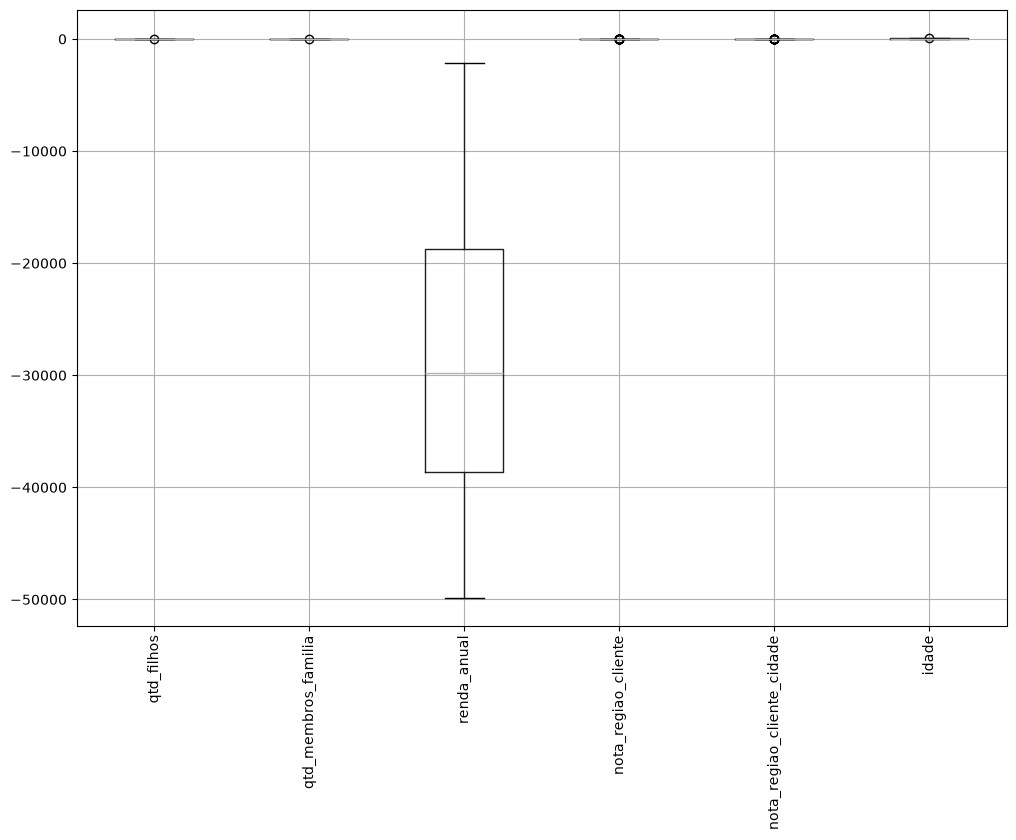

In [31]:
df_cadastro[df_cadastro['renda_anual']<0].boxplot(figsize=(12,8), )
plt.xticks(rotation=90)
plt.show()

- a distribuiçao das rendas nao sao exacerbantes, o que indica que se trata apenas de um erro de registro. Irei multiplica-los por -1 para torná-los positivos 

In [32]:
df_cadastro.loc[df_cadastro['renda_anual'] < 0,'renda_anual'] *= -1    

In [33]:
# tratando idades irreais 
df_cadastro[df_cadastro['idade']<18]
df_cadastro['idade'] = np.where(df_cadastro['idade']<18, np.nan, df_cadastro['idade'])
df_cadastro['idade'] = np.where(df_cadastro['idade']>70, np.nan, df_cadastro['idade'])

In [34]:
# dropando linhas nulas 
df_cadastro = df_cadastro.dropna()

# Tabela Empréstimos

In [35]:
df_emprestimos.head()

,,tipo_contrato,status_contrato,data_decisao,data_liberacao,data_primeiro_vencimento,data_ultimo_vencimento_original,data_ultimo_vencimento,data_encerramento,valor_solicitado,valor_credito,...,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,hora_solicitacao,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa,acompanhantes_cliente,indicador_seguro_contratado
id_cliente,id_contrato,,,,,,,,,,,,,,,,,,,,,
108129,2802425,Empréstimo em dinheiro,Aprovado,2024-08-29,None,2024-09-28,2027-08-14,None,None,607500.0,679671.0,...,Não informado,Central de atendimento,-1,quinta-feira,11:05:09,Sim,1,Não se aplica,Desacompanhado,1.0
258628,2330894,Crédito rotativo,Aprovado,2022-10-11,None,2022-11-10,2024-09-30,2024-08-01,2024-08-04,148500.0,174361.5,...,Não informado,Agências de crédito e dinheiro,-1,terça-feira,15:46:56,Sim,1,Não se aplica,Desacompanhado,1.0
267782,1182516,Crédito rotativo,Aprovado,2023-04-08,None,2023-05-08,2025-09-24,None,None,405000.0,451777.5,...,Não informado,Agências de crédito e dinheiro,-1,sábado,04:39:38,Sim,1,Não se aplica,None,1.0
275707,1543131,Crédito rotativo,Aprovado,2024-02-08,None,2024-03-09,2025-02-02,2025-02-02,2025-02-09,229500.0,241920.0,...,Não informado,Agências de crédito e dinheiro,-1,quinta-feira,08:26:26,Sim,1,Não se aplica,Desacompanhado,1.0
299391,2261993,Empréstimo em dinheiro,Cancelado,2024-09-06,None,None,None,None,None,0.0,0.0,...,Não informado,Agências de crédito e dinheiro,-1,sexta-feira,13:25:16,Sim,1,Não se aplica,None,NaN


In [36]:
# verificando percentuais de valores nulos
df_emprestimos.isnull().mean().sort_values(ascending=False)

taxa_juros_padrao                        0.996645
taxa_juros_promocional                   0.996645
data_liberacao                           0.963627
data_encerramento                        0.550905
data_ultimo_vencimento                   0.543200
percentual_entrada                       0.536076
valor_entrada                            0.536076
acompanhantes_cliente                    0.492503
data_ultimo_vencimento_original          0.449402
data_primeiro_vencimento                 0.421017
indicador_seguro_contratado              0.401828
valor_parcela                            0.241880
qtd_parcelas_planejadas                  0.241875
valor_bem                                0.234892
combinacao_produto                       0.000127
data_decisao                             0.000000
status_contrato                          0.000000
tipo_contrato                            0.000000
valor_credito                            0.000000
finalidade_emprestimo                    0.000000


In [37]:
df_emprestimos.info()

<class 'pandas.DataFrame'>
MultiIndex: 211944 entries, (np.int64(108129), np.int64(2802425)) to (np.int64(466248), np.int64(2870416))
Data columns (total 35 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   tipo_contrato                          211944 non-null  object 
 1   status_contrato                        211944 non-null  object 
 2   data_decisao                           211944 non-null  object 
 3   data_liberacao                         7709 non-null    object 
 4   data_primeiro_vencimento               122712 non-null  object 
 5   data_ultimo_vencimento_original        116696 non-null  object 
 6   data_ultimo_vencimento                 96816 non-null   object 
 7   data_encerramento                      95183 non-null   object 
 8   valor_solicitado                       211944 non-null  float64
 9   valor_credito                          211944 non-null  float64
 10  

In [38]:
# verificando nulos na tabela emprestimos 
is_null(df_emprestimos, 0.3)

COLUNAS COM % DE NAN MAIOR QUE 0.3
taxa_juros_padrao: 0.9966453402785641
taxa_juros_promocional: 0.9966453402785641
data_liberacao: 0.9636271845393123
data_encerramento: 0.5509049560261201
data_ultimo_vencimento: 0.5432000905899672
percentual_entrada: 0.5360755671309403
valor_entrada: 0.5360755671309403
acompanhantes_cliente: 0.49250273657192467
data_ultimo_vencimento_original: 0.44940172875854
data_primeiro_vencimento: 0.42101687238138374
indicador_seguro_contratado: 0.4018278413165742
quantidade de colunas nulas em funçao do limiar: 11


In [39]:
df_emprestimos.describe().T

,count,mean,std,min,25%,50%,75%,max
valor_solicitado,211944.0,176379.473956,292489.348919,0.000000,18895.500000,71820.000000,184500.000000,3.825000e+06
valor_credito,211944.0,195840.729484,316997.269417,0.000000,23661.000000,80369.900000,215951.247500,3.749054e+06
valor_bem,162160.0,223640.033460,313864.257992,0.000000,47430.000000,107816.275000,229500.000000,3.825000e+06
valor_parcela,160679.0,15802.401398,16998.124061,0.000000,5707.845000,10777.275000,20222.932500,4.749818e+05
valor_entrada,98326.0,6750.598504,20177.288202,0.000000,0.000000,1578.105000,7789.500000,1.344510e+06
percentual_entrada,98326.0,0.080110,0.108777,0.000000,0.000000,0.050661,0.108912,9.897399e-01
qtd_parcelas_planejadas,160680.0,16.904923,14.681919,0.000000,6.000000,12.000000,24.000000,8.400000e+01
taxa_juros_padrao,711.0,0.184546,0.078294,0.059121,0.160702,0.189122,0.193330,7.974470e-01
taxa_juros_promocional,711.0,0.774130,0.103323,0.424419,0.715645,0.835095,0.852537,1.000000e+00
area_venda,211944.0,305.386343,1606.805892,-1.000000,-1.000000,3.000000,84.000000,1.200000e+05


Para não assumir o risco de imputar valores que causarão viés na amostra, decidi dropar as colunas que possuem percentual de nulos acima de 30%

In [40]:
# dropando colunas com percentual alto de nulos 
drop_cols_emprestimos = ['taxa_juros_padrao', 'taxa_juros_promocional', 'data_liberacao', 'data_encerramento', 'data_ultimo_vencimento', 'percentual_entrada', 'valor_entrada', 'acompanhantes_cliente','data_ultimo_vencimento_original',  'data_primeiro_vencimento',
                        'indicador_seguro_contratado']
df_emprestimos = df_emprestimos.drop(drop_cols_emprestimos, axis=1)

In [41]:
df_emprestimos.isna().mean().sort_values(ascending=False)

valor_parcela                            0.241880
qtd_parcelas_planejadas                  0.241875
valor_bem                                0.234892
combinacao_produto                       0.000127
valor_solicitado                         0.000000
data_decisao                             0.000000
status_contrato                          0.000000
tipo_contrato                            0.000000
valor_credito                            0.000000
tipo_pagamento                           0.000000
tipo_cliente                             0.000000
finalidade_emprestimo                    0.000000
faixa_rendimento                         0.000000
tipo_portfolio                           0.000000
tipo_produto                             0.000000
categoria_bem                            0.000000
setor_vendedor                           0.000000
canal_venda                              0.000000
area_venda                               0.000000
dia_semana_solicitacao                   0.000000


In [42]:
# verificando id's duplicados
duplicated_id(df_emprestimos, 'id_cliente')

Frequencia - Contagem de Id duplicado

total id's unicos: 47952
contagem id's duplicados: 163992


Nesse caso, os Id's duplicados não significam necessariamente um problema, mas sim que o mesmo cliente contratou o serviço de emprestimo mais de uma vez. 

In [43]:
# calculando coeficiente de variaçao de valor_parcela e valor_bem para decidir o método de imputaçao ou drop
coef_cols = ['valor_bem', 'valor_parcela']
for num in coef_cols:
    std = np.std(df_emprestimos[num])
    mean = np.mean(df_emprestimos[num])
    coef = std/mean
    print('==='*50)
    print(f'desvio padrao - {num}:{round(std,2)}')
    print(f'média - {num}: {round(mean,2)}')
    print(f'{num} | coeficiente de variaçao: {round(coef,2)}')
    print()

desvio padrao - valor_bem:313863.29
média - valor_bem: 223640.03
valor_bem | coeficiente de variaçao: 1.4

desvio padrao - valor_parcela:16998.07
média - valor_parcela: 15802.4
valor_parcela | coeficiente de variaçao: 1.08



In [44]:
# plotando distribuiçao dos dados para verificar caudas
PlotDistribution().num_plot(df_emprestimos, coef_cols)

In [45]:
df_emprestimos[df_emprestimos['valor_bem'].isna()].sample(5)

,,tipo_contrato,status_contrato,data_decisao,valor_solicitado,valor_credito,valor_bem,valor_parcela,qtd_parcelas_planejadas,tipo_pagamento,finalidade_emprestimo,...,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,hora_solicitacao,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa
id_cliente,id_contrato,,,,,,,,,,,,,,,,,,,,,
145415,1269453,Crédito rotativo,Cancelado,2024-01-19,0.00,0.00,NaN,NaN,NaN,Não informado,Não informado,...,Não informado,Cartão captação externa,Não informado,Agências de crédito e dinheiro,-1,sexta-feira,08:59:15,Sim,1,Não se aplica
465971,2869741,Crédito rotativo,Cancelado,2024-10-26,4270.54,5000.00,NaN,NaN,NaN,Não informado,Não informado,...,Não informado,Cartão venda cruzada,Não informado,Agências de crédito e dinheiro,-1,quinta-feira,15:07:21,Sim,1,Desistência do cliente
465163,2867666,Financiamento de consumo,Cancelado,2023-04-04,31155.42,35259.51,NaN,NaN,NaN,Não informado,Não se aplica,...,Áudio e vídeo,Ponto de venda casa com juros,Eletrônicos de consumo,Regional ou local,200,terça-feira,15:10:40,Sim,1,Pontuação baixa
128886,1273566,Financiamento de consumo,Cancelado,2024-03-25,0.00,0.00,NaN,NaN,NaN,Não informado,Não informado,...,Celular,Dinheiro,Não informado,Agências de crédito e dinheiro,-1,segunda-feira,09:09:39,Sim,1,Não se aplica
372974,1587834,Empréstimo em dinheiro,Cancelado,2024-07-12,0.00,0.00,NaN,NaN,NaN,Não informado,Não informado,...,Não informado,Dinheiro,Não informado,Agências de crédito e dinheiro,-1,sexta-feira,18:59:33,Sim,1,Não se aplica


In [46]:
# verificando relaçao cruzada entre os valores nulos de valor_bem e valor_parcela
pd.crosstab(df_emprestimos['valor_bem'].isna(), df_emprestimos['valor_parcela'].isna(), margins=True)

valor_parcela,False,True,All
valor_bem,,,
False,151027,11133,162160
True,9652,40132,49784
All,160679,51265,211944


In [47]:
# verificando média e mediana do valor bem e valor parcela para categoria bem 
df_emprestimos.groupby('categoria_bem')[['valor_bem', 'valor_parcela']].agg(['mean', 'median', 'std', 'count'])

valor_bem                                    \
                                     mean      median            std  count   
categoria_bem                                                                 
Acessórios automotivos       89366.746062   62554.500  102689.665112    725   
Arma                        282948.002222  243900.000  265849.846798      9   
Artigos para casa           158037.465752  119592.000  136311.640572    479   
Atividade física            112640.448103   77400.000   75065.777616     29   
Celular                     116927.263226   45000.000  225157.101761  26223   
Computadores                200024.148682  115110.000  268169.539684  14926   
Educação                    167326.500000  136759.500   74941.098316      3   
Eletrônicos de consumo      186444.949891   90000.000  271040.597798  16727   
Equipamentos de escritório   69716.042290   46854.000   80215.209727    214   
Esporte e lazer             117508.576766   81733.500  128934.794954    269   
Foto e cinema                62825.280232   45639.000   53017.043551   2328   
Jardinagem                  132599.133416   79229.265  192559.346469    262   
Joias                        83165.281776   65849.850   66259.545389    563   
Materiais de construção     153551.866300  103644.000  170125.251293   2327   
Móveis                      272210.570453  145631.250  338236.491958  10366   
Não informado               286636.909488  139500.000  359258.083868  68691   
Outro                        70079.259632   52962.750   57883.780369    258   
Roupas e acessórios         208308.847840  148500.000  176981.226980   2197   
Saúde                       178507.558252  163300.500  108405.260473    123   
Seguro                      425070.000000    8505.000  723071.150493      3   
Serviço adicional           113975.756471   90738.000   77688.128906     17   
Suprimentos médicos         191118.670949  162769.500  119729.736326    374   
Turismo                     256768.189924  202500.000  175302.525294    131   
Venda direta                178280.092188  194040.000   70682.122955     32   
Veículos                    227740.160230  164250.000  264601.863211    305   
Áudio e vídeo               214300.911100  114876.000  302591.957623  14579   

                           valor_parcela                                   
                                    mean      median           std  count  
categoria_bem                                                              
Acessórios automotivos      10876.318379   8516.2050   8899.393727    694  
Arma                        22380.350000  16505.3250  16940.482816      9  
Artigos para casa           12067.578653   9993.5550   8413.818825    475  
Atividade física            12552.853393   7405.6050  11872.001176     28  
Celular                     10000.656979   6051.2850  12545.420067  24212  
Computadores                15088.159748  11250.0000  15414.054564  14633  
Educação                    17627.805000  21482.4600   9060.505865      3  
Eletrônicos de consumo      13927.213282   9445.3200  15446.148099  16698  
Equipamentos de escritório   7774.922382   6086.9250   5778.709899    212  
Esporte e lazer             12153.253516   9381.6900  13166.049790    256  
Foto e cinema                7422.702136   6072.3675   5271.372543   2140  
Jardinagem                  11350.148596   9069.5700   8713.220288    260  
Joias                       10653.316157   8348.1300   8142.444915    549  
Materiais de construção     14750.003349  11379.2400  12654.574912   2287  
Móveis                      18759.740075  13735.9125  17836.186018  10578  
Não informado               18469.176276  13015.7550  18951.713287  69661  
Outro                        8147.104272   6551.3250   6291.360716    254  
Roupas e acessórios         19001.203804  14634.8325  14948.558041   2162  
Saúde                       14342.156411  11249.4600   9540.785810    124  
Seguro                      23107.680000   1224.7200  38127.092591  

A minha ideia é preencher os valores ausentes dos dados em função das estatisticas de cada grupo

In [48]:
# inputando pela mediana dos grupos (min 30 observaçoes)
# estou aplicando um filtro sobre a categoria nao informado, pois nao tenho informaçoes sobre o tipo de bem ou produto do contrato
mask = df_emprestimos['categoria_bem'].notna() & (df_emprestimos['categoria_bem'] != 'Não informado')
for col in coef_cols:
        df_emprestimos[f'{col}_ausente'] = (df_emprestimos[col].isna().astype(int)) # flag de valor ausente da coluna
        count = df_emprestimos.groupby('categoria_bem')[col].transform('count')
        median = df_emprestimos.groupby('categoria_bem')[col].transform('median').where(count>=30)
        df_emprestimos.loc[mask, col] = df_emprestimos.loc[mask,col].fillna(median.fillna(median[mask].fillna(df_emprestimos[col].median())))    

In [49]:
print(df_emprestimos['categoria_bem'].value_counts(dropna=False))

categoria_bem
Não informado                 98847
Celular                       30338
Eletrônicos de consumo        20566
Computadores                  18743
Áudio e vídeo                 18366
Móveis                        14113
Foto e cinema                  2403
Materiais de construção        2392
Roupas e acessórios            2262
Acessórios automotivos          746
Joias                           577
Artigos para casa               492
Suprimentos médicos             384
Veículos                        312
Jardinagem                      277
Esporte e lazer                 277
Outro                           273
Equipamentos de escritório      222
Turismo                         134
Saúde                           125
Venda direta                     33
Atividade física                 29
Serviço adicional                18
Arma                              9
Educação                          3
Seguro                            3
Name: count, dtype: int64


In [50]:
# re-verificando percentuais nulos
is_null(df_emprestimos, 0.1)

COLUNAS COM % DE NAN MAIOR QUE 0.1
qtd_parcelas_planejadas: 0.24187521232023554
valor_bem: 0.14228286717246064
valor_parcela: 0.1377061865398407
quantidade de colunas nulas em funçao do limiar: 3


In [51]:
df_emprestimos.head().columns

Index(['tipo_contrato', 'status_contrato', 'data_decisao', 'valor_solicitado',
       'valor_credito', 'valor_bem', 'valor_parcela',
       'qtd_parcelas_planejadas', 'tipo_pagamento', 'finalidade_emprestimo',
       'tipo_cliente', 'faixa_rendimento', 'tipo_portfolio', 'tipo_produto',
       'categoria_bem', 'combinacao_produto', 'setor_vendedor', 'canal_venda',
       'area_venda', 'dia_semana_solicitacao', 'hora_solicitacao',
       'indicador_ultima_solicitacao_contrato',
       'indicador_ultima_solicitacao_dia', 'motivo_recusa',
       'valor_bem_ausente', 'valor_parcela_ausente'],
      dtype='str')

In [52]:
df_emprestimos['tipo_contrato'] = df_emprestimos['tipo_contrato'].str.strip().str.lower().str.replace({'crédito rotativo':'Crédito rotativo',
                                                                                        'empréstimo em dinheiro':'Empréstimo em dinheiro'})

In [53]:
# agrupando categoria_bem por valor_solicitado, valor_credito
df_emprestimos.groupby(['categoria_bem', 'tipo_contrato', 'tipo_cliente', 'faixa_rendimento'])[['valor_bem', 'valor_parcela']].agg(['mean', 'median','std', 'count', 'max', 'min']).loc['Não informado']

valor_bem  \
                                                                 mean   
tipo_contrato            tipo_cliente faixa_rendimento                  
Crédito rotativo         Novo         Não informado      88531.712674   
                                      alta               63670.814531   
                                      baixa ação        170531.502625   
                                      baixa normal      132725.703219   
                                      média             125809.874129   
...                                                               ...   
financiamento de consumo Recorrente   Não informado     127609.400588   
                                      alta               78425.476667   
                                      baixa ação        764178.750000   
                                      baixa normal      606700.000000   
                                      média             267800.495263   

                                                                   \
                                                           median   
tipo_contrato            tipo_cliente faixa_rendimento              
Crédito rotativo         Novo         Não informado      45000.00   
                                      alta               43870.50   
                                      baixa ação        116505.00   
                                      baixa normal       83380.50   
                                      média              89955.00   
...                                                           ...   
financiamento de consumo Recorrente   Não informado      45000.00   
                                      alta               67500.00   
                                      baixa ação        742500.00   
                                      baixa normal      675000.00   
                                      média             220784.53   

                                                                             \
                                                                  std count   
tipo_contrato            tipo_cliente faixa_rendimento                        
Crédito rotativo         Novo         Não informado     103826.387074   417   
                                      alta               58671.031244  3485   
                                      baixa ação        269412.975979   817   
                                      baixa normal      181871.315217  2271   
                                      média             135317.593066  2349   
...                                                               ...   ...   
financiamento de consumo Recorrente   Não informado     178189.616074    17   
                                      alta               58317.745772     9   
                                      baixa ação        651176.587268     4   
                                      baixa normal      393270.199743     9   
                                      média             226503.709183    19   

                                                                              \
                                                               max       min   
tipo_contrato            tipo_cliente faixa_rendimento                         
Crédito rotativo         Novo         Não informado     1350000.00      0.00   
                                      alta               832500.00   8950.50   
                                      baixa ação        3150000.00  12829.35   
                                      baixa normal      2845030.50  10736.05   
                                      média             1154700.00   9139.68   
...                                                            ...       ...   
financiamento de consumo Recorrente   Não informado      630000.00   4807.40   
                                      alta               180000.00  22590.00   
                                      baixa ação        1485000.00  86715.00   
   

- Devido a alta variabilidade dos dados onde a categoria_bem nao é informada, irei tratar o nulo como informaçao para a modelagem 

In [54]:
# inputando mediana para quantidade de parcelas planejadas 
df_emprestimos['qtd_parcelas_planejadas'] =df_emprestimos['qtd_parcelas_planejadas'].fillna(df_emprestimos['qtd_parcelas_planejadas'].median())
df_emprestimos = df_emprestimos.dropna(subset='combinacao_produto')

In [55]:
df_emprestimos.isnull().sum()

tipo_contrato                                0
status_contrato                              0
data_decisao                                 0
valor_solicitado                             0
valor_credito                                0
valor_bem                                30144
valor_parcela                            29172
qtd_parcelas_planejadas                      0
tipo_pagamento                               0
finalidade_emprestimo                        0
tipo_cliente                                 0
faixa_rendimento                             0
tipo_portfolio                               0
tipo_produto                                 0
categoria_bem                                0
combinacao_produto                           0
setor_vendedor                               0
canal_venda                                  0
area_venda                                   0
dia_semana_solicitacao                       0
hora_solicitacao                             0
indicador_ult

In [56]:
# separando tabela de emprestimos em tipos
cat_cols_emp = df_emprestimos.select_dtypes(exclude='number').columns
num_cols_emp = df_emprestimos.select_dtypes(include='number')

In [57]:
num_cols_emp.describe().T

,count,mean,std,min,25%,50%,75%,max
valor_solicitado,211917.0,176401.838261,292501.269206,0.0,18900.000,71864.860,184500.000,3825000.00
valor_credito,211917.0,195865.563262,317009.826672,0.0,23683.500,80397.000,216000.000,3749053.50
valor_bem,181773.0,210403.360853,299092.191665,0.0,48465.000,111964.500,225000.000,3825000.00
valor_parcela,182745.0,15072.793854,16087.582954,0.0,6051.285,10855.755,18027.135,474981.77
qtd_parcelas_planejadas,211917.0,15.719017,12.955749,0.0,10.000,12.000,18.000,84.00
area_venda,211917.0,305.420037,1606.905466,-1.0,-1.000,3.000,84.000,120000.00
indicador_ultima_solicitacao_dia,211917.0,0.996669,0.057623,0.0,1.000,1.000,1.000,1.00
valor_bem_ausente,211917.0,0.234814,0.423883,0.0,0.000,0.000,0.000,1.00
valor_parcela_ausente,211917.0,0.241788,0.428168,0.0,0.000,0.000,0.000,1.00


In [58]:
# verificando contagem de cada coluna 
for cat in cat_cols_emp:
    print(f'coluna: {cat}')
    print(df_emprestimos[cat].value_counts())
    print('---'*50)
    print()

coluna: tipo_contrato
tipo_contrato
Empréstimo em dinheiro      80195
financiamento de consumo    78379
Crédito rotativo            52771
emprestimo em dinheiro        293
credito rotativo              279
Name: count, dtype: int64
------------------------------------------------------------------------------------------------------------------------------------------------------

coluna: status_contrato
status_contrato
Aprovado                131734
Cancelado                40245
Recusado                 36354
Oferta não utilizada      3584
Name: count, dtype: int64
------------------------------------------------------------------------------------------------------------------------------------------------------

coluna: data_decisao
data_decisao
2024-06-26    309
2024-05-27    306
2024-06-04    301
2024-08-21    300
2024-07-19    294
             ... 
2025-03-06      4
2025-03-09      3
2017-02-06      1
2017-02-04      1
2025-03-08      1
Name: count, Length: 2955, dtype: int64
--

In [59]:
# trocando caracteres na coluna tipo_contrato
df_emprestimos['tipo_contrato'] =df_emprestimos['tipo_contrato'].replace({'credito rotativo':'Crédito rotativo',
                                                                        'emprestimo em dinheiro':'Empréstimo em dinheiro'}, regex=False)
df_emprestimos['tipo_contrato'].value_counts()

tipo_contrato
Empréstimo em dinheiro      80488
financiamento de consumo    78379
Crédito rotativo            53050
Name: count, dtype: int64

In [60]:
# tratando colunas de data 
df_emprestimos['data_decisao'] = pd.to_datetime(df_emprestimos['data_decisao'], format='%Y-%m-%d', errors='coerce')
# ordenando data_decisao no tempo 
df_emprestimos = df_emprestimos.sort_values('data_decisao')

# Tabela Parcelas

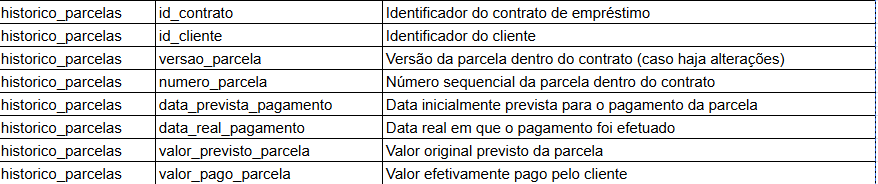

In [61]:
df_parcelas.head()

,,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
id_cliente,id_contrato,,,,,,
100193,1594684,0.0,56,2021-12-21,2021-12-21,301.86,301.86
134723,1995642,1.0,38,2021-08-09,2021-08-04,12949.20,12949.20
176364,1720935,1.0,9,2024-03-06,2024-03-04,61192.53,61192.53
154898,1439208,1.0,20,2024-08-11,2024-08-07,8851.23,8851.23
172575,1640082,1.0,4,2022-11-15,2022-11-10,8720.28,8720.28


In [62]:
# verificando id duplicados dos clientes 
duplicated_id(df_parcelas, 'id_cliente')

Frequencia - Contagem de Id duplicado

total id's unicos: 46231
contagem id's duplicados: 1618153


Semelhante ao caso anterior, a tabela de parcelas pode apresentar a presença do mesmo cliente mais de uma vez

In [63]:
df_parcelas.info()

<class 'pandas.DataFrame'>
MultiIndex: 1664384 entries, (np.int64(100193), np.int64(1594684)) to (np.int64(299839), np.int64(1028718))
Data columns (total 6 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   versao_parcela           1664384 non-null  float64
 1   numero_parcela           1664384 non-null  int64  
 2   data_prevista_pagamento  1664384 non-null  object 
 3   data_real_pagamento      1660729 non-null  object 
 4   valor_previsto_parcela   1664384 non-null  float64
 5   valor_pago_parcela       1660732 non-null  float64
dtypes: float64(3), int64(1), object(2)
memory usage: 90.2+ MB


In [64]:
# tratando datas 
datas_col = ['data_prevista_pagamento', 'data_real_pagamento']
for data in datas_col:
    print(f'Transformando coluna {data} em Datetime')
    df_parcelas[data] = pd.to_datetime(df_parcelas[data], format='%Y-%m-%d', errors='coerce')
    if (df_parcelas[data].dtype=='<M8[us]'):
        print('coluna transformada com sucesso')
        print()
    else:
        ValueError(f'Erro ao transformar a coluna {data}')

Transformando coluna data_prevista_pagamento em Datetime
coluna transformada com sucesso

Transformando coluna data_real_pagamento em Datetime
coluna transformada com sucesso



In [65]:
df_parcelas.info()

<class 'pandas.DataFrame'>
MultiIndex: 1664384 entries, (np.int64(100193), np.int64(1594684)) to (np.int64(299839), np.int64(1028718))
Data columns (total 6 columns):
 #   Column                   Non-Null Count    Dtype         
---  ------                   --------------    -----         
 0   versao_parcela           1664384 non-null  float64       
 1   numero_parcela           1664384 non-null  int64         
 2   data_prevista_pagamento  1664384 non-null  datetime64[us]
 3   data_real_pagamento      1660729 non-null  datetime64[us]
 4   valor_previsto_parcela   1664384 non-null  float64       
 5   valor_pago_parcela       1660732 non-null  float64       
dtypes: datetime64[us](2), float64(3), int64(1)
memory usage: 90.2 MB


# Definição do Target

Estou definindo o target (default) com base à quantidade de dias de atraso. Por conta de ser uma carteira de clientes pequena, utilizarei uma aborgem mais agressiva para classificar quem é inadimplente e quem nao é

In [66]:
# 30 dias de atraso -> default
new_df_parcelas = target_create(30)
new_df_parcelas['TARGET'].value_counts(normalize=True)

TARGET
0    0.985274
1    0.014726
Name: proportion, dtype: float64

# exportação das bases de dados 

In [67]:
# funçao para exportaçao em batch das bases
def export_tables():
    tables = {
        'tabela_cadastral_tratada.parquet': df_cadastro.reset_index(),
        'tabela_emprestimos_tratada.parquet': df_emprestimos.reset_index(),
        'tabela_parcelas.parquet': df_parcelas.reset_index()}
    for i, table in tables.items():
        data_exp = os.path.join('..', 'data', 'processed', i)
        table.to_parquet(data_exp, index=False)
        print(f'tabela {i} criada')
        print()
        


In [68]:
# fazendo uso da funçao 
export_tables()

tabela tabela_cadastral_tratada.parquet criada

tabela tabela_emprestimos_tratada.parquet criada

tabela tabela_parcelas.parquet criada

